# Milestone 3 — Tracking: persistent IDs + majority-vote class

**Problem after Milestone 2:** the detector works on each frame alone. The same player is a new, unrelated box in every frame, so we cannot say "player 7 ran 60 m". Also the class can flicker: one goalkeeper is called `goalkeeper` in 90 frames and `player` in 10.

**Fix:**
1. **Tracking** (ByteTrack): link boxes across frames and give each person a `tracker_id` that stays the same.
2. **Majority vote:** decide each track's class from *all* its frames, so flicker disappears.

Plan:
1. Concepts (read first)
2. Setup
3. Detect the whole clip once and cache it (so tracker experiments take seconds, not minutes)
4. Run ByteTrack
5. Look at the result as a table and as a picture (timeline of IDs)
6. Fix class flicker with a vote
7. Find suspicious ID switches
8. Experiments: how `lost_buffer` and thresholds change the result
9. Render the video and save `tracks.csv` for Milestones 4 to 7

## 1. Concepts

**Tracking by detection.** The detector gives boxes per frame. The tracker's job is *association*: for every box in frame t, decide which existing track it continues (or whether it starts a new one).

**How a track predicts where to look.** Each track keeps a simple motion model (a **Kalman filter**): from the last few positions it predicts where the box should be in the next frame. Then it matches predicted boxes with new boxes by **IoU** (box overlap, same IoU as in Milestone 2): the best overlaps get linked.
> Tabular analogy: a forecast (where should it be?) plus a matching step (which new row is closest to each forecast?).

**What is special about ByteTrack.** Most trackers throw away low-confidence boxes. ByteTrack matches in **two rounds**:
1. High-confidence boxes are matched to tracks first.
2. The tracks that are still unmatched get a second chance against the **low-confidence** boxes. A partly hidden player usually has a low score, but its box still overlaps the prediction, so the track survives instead of breaking.

**Track life cycle**
| State | Meaning |
|---|---|
| tentative | new box with high enough confidence; needs `minimum_consecutive_frames` matches before it gets an ID |
| tracked | matched this frame |
| lost | no match; kept alive for `lost_track_buffer` frames, still predicting its position |
| removed | lost for too long, deleted. If the person comes back, they get a **new ID** |

**Parameters you will tune**
| Parameter | Bigger value means | Risk |
|---|---|---|
| `track_activation_threshold` | fewer ghost tracks | real players with low confidence never start |
| `lost_track_buffer` | bridges longer occlusions with the same ID | an ID may be reused for a different person |
| `minimum_matching_threshold` | stricter linking | tracks break more often |
| `minimum_consecutive_frames` | fewer one-frame ghosts | IDs appear a few frames late |

**Two failure types you must know**
- **Fragmentation:** one person gets several IDs over time (track broke). Symptom: too many unique IDs.
- **ID switch:** two people swap IDs (usually when they cross or tackle). Symptom: an ID's box suddenly jumps to someone else.

**Our design choices**
- **The ball is not tracked** by ByteTrack. It is tiny, fast and often missing, so a motion model fails. We keep the best ball box per frame and fill gaps in Milestone 5.
- **Class-agnostic NMS** before tracking: the model can output a `player` box and a `goalkeeper` box on the same person. Without this they become two tracks.
- **Majority vote:** class of a track = class with the largest sum of confidences over the whole track.

In [1]:
%pip install -q supervision

Note: you may need to restart the kernel to use updated packages.


In [2]:
import sys, pickle, time
from pathlib import Path
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
import supervision as sv

ROOT = Path.cwd().parent                      # run Jupyter from notebooks/
sys.path.insert(0, str(ROOT / "src"))

from football_tracking.detection import Detector
from football_tracking.pitch import keep_on_pitch, pitch_mask
from football_tracking.video_io import video_info, iter_frames, VideoWriter
from football_tracking.tracking import (PlayerTracker, TrackerConfig, TrackAnnotator, tracks_to_frame,
    vote_classes, apply_votes, class_flicker, track_summary, id_switch_suspects, OnlineClassVoter)

CLIP_NAME = "08fd33_0.mp4"                   # same clip as before
VIDEO = ROOT / "data" / "raw" / CLIP_NAME
WEIGHTS = ROOT / "models" / "football_yolo11s_1280.pt"
USE_PITCH_FILTER = True                      # drops boxes whose feet are off the grass
OUT = ROOT / "outputs"; OUT.mkdir(exist_ok=True)
CACHE = OUT / f"dets_{VIDEO.stem}_{WEIGHTS.stem}_pf{int(USE_PITCH_FILTER)}.pkl"

assert VIDEO.exists(), f"video missing: {VIDEO}"
assert WEIGHTS.exists(), f"weights missing: {WEIGHTS} (copy runs/.../best.pt there, see notebook 02)"
info = video_info(VIDEO); print(info)

{'width': 1920, 'height': 1080, 'fps': 25.0, 'frame_count': 750, 'duration_s': 30.0}


## 2. Detect the whole clip once, cache it

Detection is the slow part (about 20 to 40 s for the clip on your GPU). Tracker settings only change how boxes are *linked*, so we run the detector once and save the boxes. Every experiment below then re-runs only the tracker, which takes about a second.

In [3]:
det = Detector(str(WEIGHTS), conf=0.25, imgsz=1280)
names, BALL = det.names, det.class_id("ball")
print(names, "ball id =", BALL, "| device:", det.device)

if CACHE.exists():
    raw = pickle.load(open(CACHE, "rb"))
    print("loaded cache:", CACHE.name, len(raw), "frames")
else:
    raw, t0 = [], time.time()
    for i, frame in iter_frames(VIDEO):
        d = det.detect(frame)
        if USE_PITCH_FILTER:
            d = keep_on_pitch(d, pitch_mask(frame), exempt_classes=[BALL])
        raw.append((d.xyxy.copy(), d.confidence.copy(), d.class_id.copy()))
    pickle.dump(raw, open(CACHE, "wb"))
    print(f"detected {len(raw)} frames in {time.time()-t0:.0f}s, cached to {CACHE.name}")

def to_dets(item):
    xyxy, conf, cid = item
    return sv.Detections(xyxy=xyxy, confidence=conf, class_id=cid)

{0: 'ball', 1: 'goalkeeper', 2: 'player', 3: 'referee'} ball id = 0 | device: cuda
loaded cache: dets_08fd33_0_football_yolo11s_1280_pf1.pkl 750 frames


## 3. Run ByteTrack

`run_tracker(cfg)` feeds the cached detections frame by frame to the tracker. **Order matters**: a tracker is a state machine, so frames must go in 0, 1, 2, ... and a fresh tracker is created for each run.

In [4]:
def run_tracker(cfg: TrackerConfig):
    tracker = PlayerTracker(info["fps"], BALL, cfg)
    return [tracker.update(to_dets(item)) for item in raw]

cfg = TrackerConfig()                         # defaults: lost_buffer=50, activation 0.25, ...
t0 = time.time()
per_frame = run_tracker(cfg)
print(f"tracked {len(per_frame)} frames in {time.time()-t0:.1f}s")
df = tracks_to_frame(per_frame, names)
df.head(10)

d:\codes\football pretrained\src\football_tracking\tracking.py:64: FutureWarning: The `ByteTrack` was deprecated since v0.28.0. It will be removed in v0.31.0.
  self.tracker = sv.ByteTrack(


tracked 750 frames in 9.1s


,frame,tracker_id,class_id,class_name,conf,x1,y1,x2,y2
0,1,2,2,player,0.866673,1013.630310,433.867249,1034.616455,472.453003
1,1,3,2,player,0.863333,1259.112793,540.216858,1289.164795,589.742004
2,1,7,2,player,0.840457,741.396240,550.411621,760.255188,601.746582
3,1,6,2,player,0.823488,1342.630615,629.618896,1362.417969,683.721741
4,1,5,2,player,0.822941,1288.309082,432.709167,1303.571289,470.282776
5,1,12,2,player,0.821099,956.962280,487.814117,972.722717,531.032715
6,1,9,2,player,0.814517,1202.486694,526.676331,1219.487061,573.505249
7,1,8,2,player,0.810244,1346.753906,495.691406,1360.177734,542.433105
8,1,1,2,player,0.810085,865.732056,638.492065,887.749023,688.419250
9,1,11,2,player,0.803319,1186.139893,436.686676,1197.680908,473.596344


In [5]:
print(track_summary(df))
print("class counts (rows):"); print(df.class_name.value_counts())

{'ids_created': 58, 'expected_people': 25, 'median_track_len': 109.5, 'short_tracks_lt_25f': 22, 'tracks_with_gaps': 25, 'people_per_frame': 22.59279038718291}
class counts (rows):
class_name
player        15152
referee        1655
ball            531
goalkeeper      115
Name: count, dtype: int64


**How to read `track_summary`**
- `ids_created` should be *close to the number of people who appear*: about 22 players plus referees if everybody is in the clip, **fewer** when the camera follows part of the pitch. If it is 3x that, tracks break (fragmentation).
- `short_tracks_lt_25f`: IDs shorter than 1 second. Mostly ghosts or fragments.
- `tracks_with_gaps`: an ID disappeared and came back with the **same** ID. This is the tracker doing its job during occlusions.
- `people_per_frame`: should be similar to what you count by eye on a typical frame.

## 4. See the tracks: a timeline of IDs

Each horizontal bar is one `tracker_id`, from the first frame it appeared to the last. A healthy clip has long bars. Many tiny bars = fragmentation. Camera cuts show up as many bars ending and starting at the same frame.

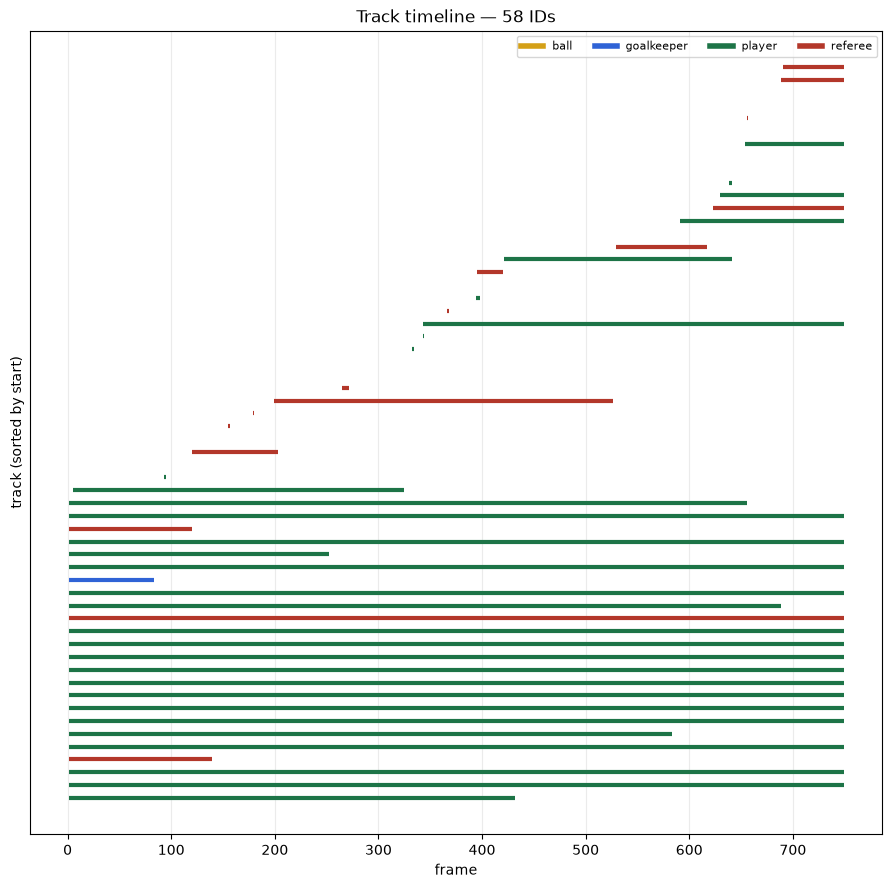

In [6]:
def timeline(d, class_col="class_id", title=""):
    p = d[d.tracker_id != -1]
    spans = p.groupby("tracker_id").frame.agg(["min", "max", "count"]).sort_values("min")
    cls = p.groupby("tracker_id")[class_col].agg(lambda s: s.value_counts().index[0])
    colour = {names[k]: c for k, c in zip(sorted(names), ["#d4a017", "#2f63d6", "#1d7447", "#b3372a"])}
    fig, ax = plt.subplots(figsize=(11, max(3, 0.18 * len(spans))))
    for y, (tid, r) in enumerate(spans.iterrows()):
        ax.hlines(y, r["min"], r["max"], color=colour[names[int(cls[tid])]], lw=3)
    ax.set_xlabel("frame"); ax.set_ylabel("track (sorted by start)"); ax.set_title(title)
    ax.set_yticks([]); ax.grid(axis="x", alpha=.25)
    for n, c in colour.items(): ax.plot([], [], color=c, lw=4, label=n)
    ax.legend(loc="upper right", ncol=4, fontsize=8); plt.show()

timeline(df, "class_id", f"Track timeline — {len(df[df.tracker_id!=-1].tracker_id.unique())} IDs")

## 5. Look at frames

Boxes are coloured **by track ID**, so a colour should follow one player. The trail shows where each ID has been in the last second. Pick frames far apart and check that the same person keeps the same number.

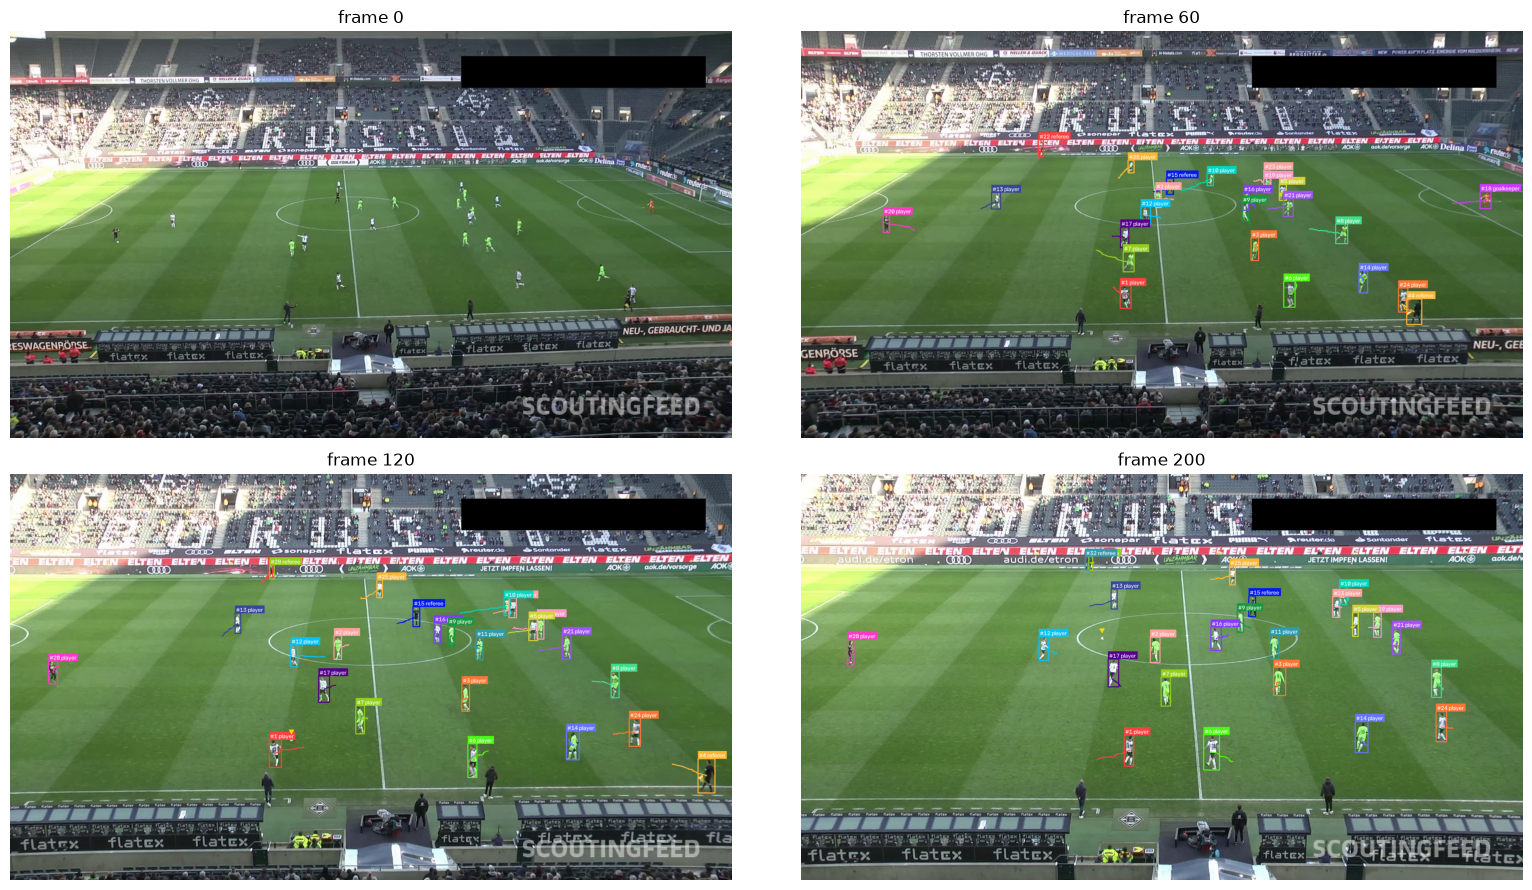

In [7]:
FRAMES = [0, 60, 120, 200]                    # edit: frames to inspect (must be < clip length)
# trails need the previous frames to be passed through the annotator in order, so we play from frame 0
ann = TrackAnnotator(trail=30)
shown = {}
for i, f in iter_frames(VIDEO, max_frames=max(FRAMES) + 1):
    out = ann(f, per_frame[i], names)
    if i in FRAMES: shown[i] = out
fig, axs = plt.subplots(2, 2, figsize=(16, 9))
for ax, i in zip(axs.ravel(), FRAMES):
    ax.imshow(cv2.cvtColor(shown[i], cv2.COLOR_BGR2RGB)); ax.set_title(f"frame {i}"); ax.axis("off")
plt.tight_layout(); plt.show()

## 6. Fix class flicker with a vote

Each track currently carries the class the detector gave **in each frame**. We count how often the class changes along a track, then replace the class by the track's weighted-majority class.

In [8]:
fl_before = class_flicker(df, "class_id")
votes = vote_classes(df)
dfv = apply_votes(df, votes, names)
fl_after = class_flicker(dfv, "voted_class_id")

print("tracks whose class changes:   before", int((fl_before.class_changes > 0).sum()),
      "| after", int((fl_after.class_changes > 0).sum()))
print("total class changes:          before", int(fl_before.class_changes.sum()),
      "| after", int(fl_after.class_changes.sum()))
fl_before.sort_values("class_changes", ascending=False).head(8)

tracks whose class changes:   before 7 | after 0
total class changes:          before 51 | after 0


,tracker_id,frames,class_changes,n_classes
19,20,252,26,2
11,12,749,10,2
17,18,83,6,2
23,24,652,4,2
10,11,740,2,2
16,17,749,2,2
14,15,744,1,2
2,3,749,0,1


track #20: 252 frames | voted class = player
class_name
player        214
goalkeeper     38


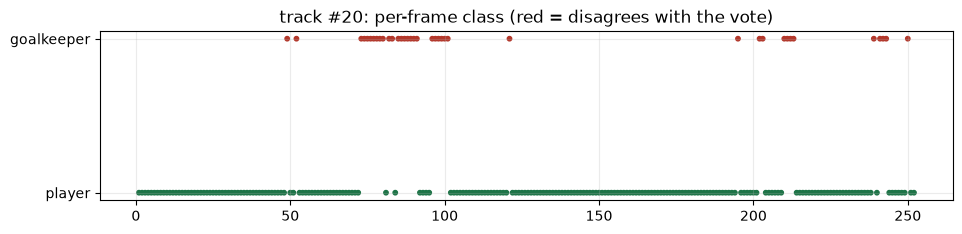

In [9]:
# one flickering track in detail: the class the detector said per frame vs the voted class
tid = int(fl_before.sort_values("class_changes", ascending=False).iloc[0].tracker_id)
g = dfv[dfv.tracker_id == tid].sort_values("frame")
print(f"track #{tid}: {len(g)} frames | voted class = {names[votes[tid]]}")
print(g.class_name.value_counts().to_string())
fig, ax = plt.subplots(figsize=(11, 2.2))
ax.scatter(g.frame, g.class_name, s=10, c=np.where(g.class_id == votes[tid], "#1d7447", "#b3372a"))
ax.set_title(f"track #{tid}: per-frame class (red = disagrees with the vote)"); ax.grid(alpha=.25); plt.show()

**Why a confidence-weighted vote?** A 0.9 vote for `goalkeeper` should count more than a 0.3 vote for `player`. A plain count is available with `weight_by_conf=False`.

**Offline vs online.** Here we have the whole clip, so the vote sees every frame of each track (best accuracy). In a live system you cannot see the future: `OnlineClassVoter` keeps a running vote, so the label may change in the first frames and then settles. We use the offline vote for the final video and keep the online one for a possible Streamlit live mode.

**Limit of voting.** It fixes *flicker*, not a *systematic* error. If the model really thinks a referee is a player in most frames, the vote makes that wrong answer permanent. That is a training-data problem (add more labelled referees), not a tracker problem.

## 7. Hunt for ID switches

A person moves a few pixels per frame. If a track's centre jumps more than ~150 px between two frames, the ID probably moved to someone else, or the camera cut. This list tells you **where to watch the video**.

In [10]:
sus = id_switch_suspects(df, max_jump_px=150)
print(len(sus), "suspicious jumps")
sus.head(15)

0 suspicious jumps


,frame,tracker_id,jump_per_frame


In [11]:
# frames where MANY tracks jump at once = camera cut (not a tracker error)
if len(sus):
    per = sus.groupby("frame").size().sort_values(ascending=False)
    print("frames with the most simultaneous jumps (likely camera cuts):"); print(per.head(5))

## 8. Experiments: what do the parameters change?

We re-run only the tracker (the detections are cached). Change **one** setting at a time.

In [12]:
rows = []
for name, c in {
    "default (buffer 50)":        TrackerConfig(),
    "buffer 10 (forgets fast)":   TrackerConfig(lost_buffer=10),
    "buffer 100 (remembers)":     TrackerConfig(lost_buffer=100),
    "activation 0.5 (strict)":    TrackerConfig(activation_threshold=0.5),
    "activation 0.15 (loose)":    TrackerConfig(activation_threshold=0.15),
    "match 0.6 (lenient link)":   TrackerConfig(match_threshold=0.6),
    "match 0.9 (lenient link)":   TrackerConfig(match_threshold=0.9),
    "min_consecutive 1":          TrackerConfig(min_consecutive=1),
}.items():
    d = tracks_to_frame(run_tracker(c), names)
    s = track_summary(d); s["suspect_jumps"] = len(id_switch_suspects(d)); s["setting"] = name
    rows.append(s)
exp = pd.DataFrame(rows).set_index("setting")[["ids_created", "short_tracks_lt_25f", "median_track_len",
                                               "tracks_with_gaps", "people_per_frame", "suspect_jumps"]]
exp.round(1)

,ids_created,short_tracks_lt_25f,median_track_len,tracks_with_gaps,people_per_frame,suspect_jumps
setting,,,,,,
default (buffer 50),58,22,109.5,25,22.6,0
buffer 10 (forgets fast),59,23,94.0,26,22.6,0
buffer 100 (remembers),58,22,109.5,26,22.6,0
activation 0.5 (strict),41,9,396.0,20,22.3,0
activation 0.15 (loose),61,23,103.0,29,22.6,0
match 0.6 (lenient link),225,166,2.0,66,22.1,0
match 0.9 (lenient link),49,14,211.0,28,22.7,0
min_consecutive 1,58,22,109.5,25,22.6,0


**What to look for**
- `lost_buffer` 10 → 100: `ids_created` should **fall** (fewer fragments), `tracks_with_gaps` should **rise**. Too large and `suspect_jumps` can rise (a lost ID gets reused for someone else).
- Strict activation: fewer short tracks but `people_per_frame` drops (real players missing).
- Lenient `match_threshold`: tracks break less but ID switches are more likely.
- **There is no single best setting.** Choose the one with few fragments *and* few suspect jumps, then **confirm by watching the video**. Numbers only tell you where to look.

In [13]:
rows  = []
for act in [0.4, 0.5, 0.6, 0.7]:
    for match in [0.8, 0.9, 0.95]:
        c = TrackerConfig(activation_threshold=act, match_threshold=match)
        d = tracks_to_frame(run_tracker(c), names)
        s = track_summary(d); s["suspect_jumps"] = len(id_switch_suspects(d))
        s["activation"], s["match"] = act, match
        rows.append(s)
grid = pd.DataFrame(rows).set_index(["activation", "match"])[["ids_created", "short_tracks_lt_25f", "median_track_len",
                                                              "tracks_with_gaps", "people_per_frame", "suspect_jumps"]]
grid.round(1)

ids_created  short_tracks_lt_25f  median_track_len  \
activation match                                                       
0.4        0.80            44                   11             346.0   
           0.90            43                   10             372.0   
           0.95            39                    7             493.0   
0.5        0.80            41                    9             396.0   
           0.90            39                    9             646.0   
           0.95            37                    7             684.0   
0.6        0.80            36                    5             709.5   
           0.90            33                    3             735.0   
           0.95            33                    3             735.0   
0.7        0.80            35                    3             676.0   
           0.90            33                    2             725.0   
           0.95            32                    2             724.5   

                  tracks_with_gaps  people_per_frame  suspect_jumps  
activation match                                                     
0.4        0.80                 22              22.5              0  
           0.90                 23              22.6              0  
           0.95                 21              22.6              0  
0.5        0.80                 20              22.3              0  
           0.90                 16              22.4              0  
           0.95                 15              22.4              0  
0.6        0.80                 17              22.2              0  
           0.90                 15              22.2              0  
           0.95                 15              22.2              0  
0.7        0.80                 13              21.6              0  
           0.90                 14              21.6              0  
           0.95                 14              21.6              0

## 9. Render the video and save the track table

Class shown = voted class. Colour = track ID. We write `tracks.csv` because Milestones 4 to 7 read it instead of re-running detection.

In [14]:
from football_tracking.tracking import ghost_track_ids, drop_tracks
CHOSEN = TrackerConfig(activation_threshold=0.4, match_threshold=0.9)
per_frame = run_tracker(CHOSEN)
df = tracks_to_frame(per_frame, names)
ghosts = ghost_track_ids(df, min_len=25, min_conf=0.6)
print(len(ghosts), "ghost tracks removed:", sorted(ghosts))
per_frame = drop_tracks(per_frame, ghosts)
df = tracks_to_frame(per_frame, names)
votes = vote_classes(df)
dfv = apply_votes(df, votes, names)

ann = TrackAnnotator(trail=30)
out_path = OUT / "m3_tracked.mp4"
with VideoWriter(out_path, info["fps"], info["width"], info["height"]) as w:
    for i, frame in iter_frames(VIDEO):
        d = per_frame[i]
        cls = (np.array([votes.get(int(t), int(c)) if t != -1 else int(c)
                         for t, c in zip(d.tracker_id, d.class_id)]) if len(d) else d.class_id)
        w.write(ann(frame, d, names, class_ids=cls))
dfv.to_csv(OUT / "m3_tracks.csv", index=False)
print("saved:", out_path, "and", OUT / "m3_tracks.csv")
print(track_summary(dfv))

2 ghost tracks removed: [27, 30]
saved: d:\codes\football pretrained\outputs\m3_tracked.mp4 and d:\codes\football pretrained\outputs\m3_tracks.csv
{'ids_created': 41, 'expected_people': 25, 'median_track_len': 398.0, 'short_tracks_lt_25f': 8, 'tracks_with_gaps': 23, 'people_per_frame': 22.572763684913216}


In [15]:
REF = det.class_id("referee")
N = len(raw)

# 1) raw detector output, before tracking
raw_ref = np.array([(cid == REF).sum() for _, _, cid in raw])
conf_ref = np.concatenate([c[cid == REF] for _, c, cid in raw])
print("RAW detector: avg referee boxes/frame =", raw_ref.mean().round(2),
      "| frames with 2+ referees =", (raw_ref >= 2).mean().round(2))
print("referee confidence:", pd.Series(conf_ref).describe().round(2)[["min", "25%", "50%", "75%", "max"]].to_dict())

# 2) after tracking with the chosen settings
trk = tracks_to_frame(run_tracker(CHOSEN), names)
trk_ref = trk[trk.class_id == REF].groupby("frame").size().reindex(range(N), fill_value=0).to_numpy()
print("TRACKED: avg referee boxes/frame =", trk_ref.mean().round(2),
      "| frames with 2+ referees =", (trk_ref >= 2).mean().round(2))

# 3) longest stretches (in seconds) with fewer than 2 referees
def runs(mask, fps):
    out, start = [], None
    for i, m in enumerate(mask):
        if m and start is None: start = i
        if (not m or i == len(mask) - 1) and start is not None:
            end = i if m else i - 1
            out.append((start, end, round((end - start + 1) / fps, 1))); start = None
    return sorted(out, key=lambda r: -r[2])[:5]
print("gaps, raw detector :", runs(raw_ref < 2, info["fps"]))
print("gaps, after tracker:", runs(trk_ref < 2, info["fps"]))

RAW detector: avg referee boxes/frame = 2.51 | frames with 2+ referees = 0.95
referee confidence: {'min': 0.25, '25%': 0.6, '50%': 0.74, '75%': 0.82, 'max': 0.92}
TRACKED: avg referee boxes/frame = 2.21 | frames with 2+ referees = 0.92
gaps, raw detector : [(576, 581, 0.2), (255, 256, 0.1), (259, 260, 0.1), (269, 271, 0.1), (277, 278, 0.1)]
gaps, after tracker: [(574, 585, 0.5), (650, 656, 0.3), (618, 622, 0.2), (685, 688, 0.2), (164, 165, 0.1)]


In [16]:
rows = []
for name, c in {
    "act 0.6 / match 0.9 (current)": TrackerConfig(activation_threshold=0.6, match_threshold=0.9),
    "act 0.5 / match 0.9":           TrackerConfig(activation_threshold=0.5, match_threshold=0.9),
    "act 0.4 / match 0.9":           TrackerConfig(activation_threshold=0.4, match_threshold=0.9),
    "act 0.6, min_consec 1":         TrackerConfig(activation_threshold=0.6, match_threshold=0.9, min_consecutive=1),
    "act 0.6, nms 0.9":              TrackerConfig(activation_threshold=0.6, match_threshold=0.9, nms_iou=0.9),
    "act 0.4, nms 0.9":              TrackerConfig(activation_threshold=0.4, match_threshold=0.9, nms_iou=0.9),
}.items():
    d = tracks_to_frame(run_tracker(c), names)
    r = d[d.class_id == REF].groupby("frame").size().reindex(range(N), fill_value=0).to_numpy()
    s = track_summary(d)
    rows.append({"setting": name, "frames_2plus_ref": round((r >= 2).mean(), 2),
                 "longest_ref_gap_s": runs(r < 2, info["fps"])[0][2],
                 "ids_created": s["ids_created"], "short_tracks": s["short_tracks_lt_25f"],
                 "people_per_frame": round(s["people_per_frame"], 1)})
pd.DataFrame(rows).set_index("setting")

,frames_2plus_ref,longest_ref_gap_s,ids_created,short_tracks,people_per_frame
setting,,,,,
act 0.6 / match 0.9 (current),0.74,3.3,33,3,22.2
act 0.5 / match 0.9,0.87,0.6,39,9,22.4
act 0.4 / match 0.9,0.92,0.5,43,10,22.6
"act 0.6, min_consec 1",0.75,3.3,33,3,22.2
"act 0.6, nms 0.9",0.75,3.3,35,5,22.2
"act 0.4, nms 0.9",0.92,0.5,60,22,22.7


## 10. Check yourself

**Questions** (answer on paper first):
1. Why can a tracker keep an ID through a few frames where the detector missed the player?
2. What does ByteTrack do with low-confidence boxes that older trackers discard?
3. What is the difference between fragmentation and an ID switch? Which one shows up as "too many IDs"?
4. Why do we run class-agnostic NMS before tracking?
5. Why is the ball not given to ByteTrack?
6. Majority vote fixed the goalkeeper flicker. Name one error it **cannot** fix.
7. Raising `lost_buffer` from 50 to 100: what improves, what can get worse?

**Do it yourself**
- Watch `m3_tracked.mp4`. Write down 3 frame numbers where an ID changes person and check them against `id_switch_suspects`.
- Count the people visible in one frame and compare with `people_per_frame`.
- Fill in for the README: unique IDs ____ | median track length ____ | class changes before ____ after ____.

**Pitfalls**
- Never call `tracker.update` on frames out of order, or on a shuffled list.
- Create a **new** tracker for each clip or experiment (or call `reset()`), otherwise old tracks leak into the next run.
- After a **camera cut**, IDs can all change: that is expected in broadcast video. Milestone 6 (pitch coordinates) is what lets us re-link people across cuts later.
- `minimum_consecutive_frames > 1` means a player appears with an ID a frame or two late. Not a bug.